# Paper Figures

Clean plotting notebook for the paper. The figure cells below use precomputed tables from `plotting_data/`, resolved relative to the repository root.

The last section contains concise Polars recipes showing how each plotting table can be regenerated from raw database-specific tables, plus the DOI-based direct comparison workflow.


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import numpy as np
import polars as pl
import seaborn as sns

try:
    import geopandas as gpd
    from mpl_toolkits.axes_grid1 import make_axes_locatable
except ImportError:
    gpd = None
    make_axes_locatable = None


In [4]:
def find_repo_root(start: Path) -> Path:
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / 'plotting_data').exists() and (candidate / 'scripts').exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd())
PLOTTING_DIR = REPO_ROOT / 'plotting_data'
OUTPUT_DIR = REPO_ROOT / 'paper_figures_output'
WORLD_URL = 'https://www.naturalearthdata.com/http//www.naturalearthdata.com/download/110m/cultural/ne_110m_admin_0_countries.zip'
WORLD_FALLBACK_URL = 'https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip'
WORLD_PATH = PLOTTING_DIR / 'ne_110m_admin_0_countries.zip'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def set_pub_defaults():
    plt.style.use('default')
    mpl.rcParams.update({
        'font.size': 8,
        'axes.labelsize': 8,
        'axes.titlesize': 9,
        'xtick.labelsize': 8,
        'ytick.labelsize': 8,
        'legend.fontsize': 8,
        'lines.linewidth': 1.8,
        'axes.linewidth': 0.8,
        'figure.dpi': 140,
        'savefig.dpi': 300,
    })


def format_large_tick(value, _pos=None):
    if abs(value) >= 1_000_000:
        return f'{value / 1_000_000:.1f}M'
    if abs(value) >= 1_000:
        return f'{value / 1_000:.0f}K'
    return f'{value:.0f}'


def read_tsv(name: str) -> pl.DataFrame:
    return pl.read_csv(
        PLOTTING_DIR / name,
        separator='	',
        null_values=['', 'NaN', 'null', 'None'],
        try_parse_dates=False,
    )


def load_world():
    if gpd is None:
        print('geopandas is not available; map panels will be skipped.')
        return None

    WORLD_PATH.parent.mkdir(parents=True, exist_ok=True)
    if not WORLD_PATH.exists():
        from urllib.request import Request, urlopen

        headers = {
            'User-Agent': 'Mozilla/5.0',
            'Accept': '*/*',
        }
        for url in [WORLD_URL, WORLD_FALLBACK_URL]:
            try:
                print(f'Downloading Natural Earth countries from {url} ...')
                req = Request(url, headers=headers)
                with urlopen(req) as response, WORLD_PATH.open('wb') as fh:
                    fh.write(response.read())
                break
            except Exception as exc:
                print(f'Could not download Natural Earth data from {url}: {exc}')
        if not WORLD_PATH.exists():
            return None

    world = gpd.read_file(WORLD_PATH)
    return world.query('SOVEREIGNT != "Antarctica"')


set_pub_defaults()


In [5]:
wos_share = read_tsv('wos_share.tsv')
openalex_share = read_tsv('openalex_share.tsv')
wos_author_country = read_tsv('wos_author_country.tsv')
openalex_author_country = read_tsv('openalex_author_country.tsv')
wos_funder_country = read_tsv('wos_funder_country.tsv')
openalex_funder_country = read_tsv('openalex_funder_country.tsv')
wos_funder_types = read_tsv('wos_funder_types.tsv')

dimensions_share_path = PLOTTING_DIR / 'dimensions_share.tsv'
dimensions_share = (
    read_tsv('dimensions_share.tsv')
    if dimensions_share_path.exists()
    else None
)

world = load_world()


## Funding coverage over time


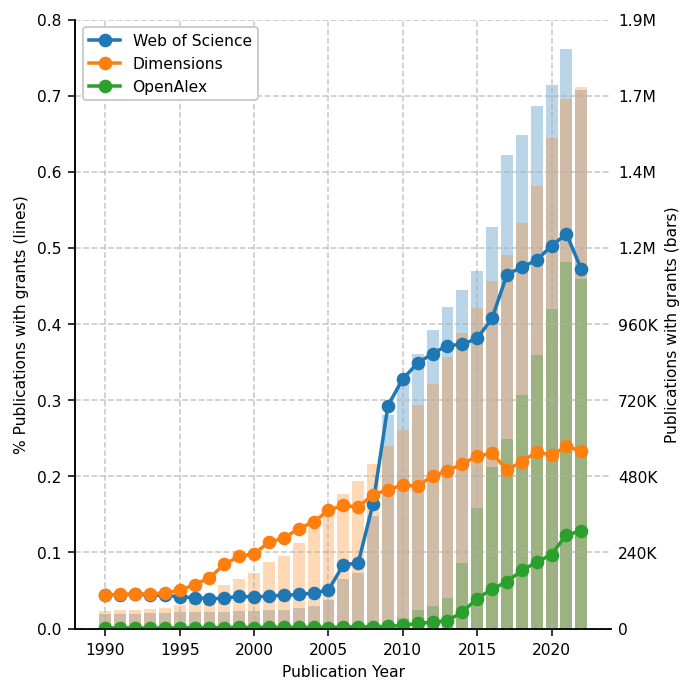

In [6]:
df = (
    wos_share
    .filter(pl.col('pubyear').is_not_null() & (pl.col('pubyear') >= 1990) & (pl.col('pubyear') < 2023))
    .with_columns(pl.col('pubyear').cast(pl.Int64))
    .sort('pubyear')
    .to_pandas()
)

oa_df = (
    openalex_share
    .filter(pl.col('publication_year').is_not_null() & (pl.col('publication_year') >= 1990) & (pl.col('publication_year') < 2023))
    .with_columns(pl.col('publication_year').cast(pl.Int64))
    .sort('publication_year')
    .to_pandas()
)

dim_df = None
if dimensions_share is not None:
    dim_df = (
        dimensions_share
        .filter(pl.col('year').is_not_null() & (pl.col('year') < 2023))
        .sort('year')
        .to_pandas()
    )

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_ylim(0, 0.8)
ax2 = ax.twinx()

ax.plot(df['pubyear'], df['share_with_grant'], marker='o', linestyle='-', label='Web of Science', zorder=2)
if dim_df is not None:
    ax.plot(dim_df['year'], dim_df['share_has_grant'], marker='o', linestyle='-', label='Dimensions', zorder=2)
ax.plot(oa_df['publication_year'], oa_df['share_with_grant'], marker='o', linestyle='-', label='OpenAlex', zorder=2)

ax2.bar(df['pubyear'], df['pubs_with_grant'], alpha=0.3, color='tab:blue', label='Web of Science', zorder=1)
if dim_df is not None:
    ax2.bar(dim_df['year'], dim_df['pubs_with_grant'], alpha=0.3, color='tab:orange', label='Dimensions', zorder=1)
ax2.bar(oa_df['publication_year'], oa_df['pubs_with_grant'], alpha=0.3, color='tab:green', label='OpenAlex', zorder=1)

leg1 = ax.legend(loc='upper left', frameon=True, framealpha=1)
leg1.get_frame().set_facecolor('white')
leg1.set_zorder(10_000)

ax.set_xlim(right=2024)
ax2.set_zorder(0)
ax.patch.set_alpha(0)
ax.set_zorder(1)

ax.set_xlabel('Publication Year')
ax.set_ylabel('% Publications with grants (lines)')
ax2.set_ylabel('Publications with grants (bars)')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(format_large_tick))
ax.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
ax2.relim()
ax2.autoscale_view()

def map_ticks_from_ax_to_ax2(ax_ticks, ax, ax2):
    y1min, y1max = ax.get_ylim()
    y2min, y2max = ax2.get_ylim()
    scale = (y2max - y2min) / (y1max - y1min)
    return [y2min + (y - y1min) * scale for y in ax_ticks]

ax_ticks = ax.get_yticks()
ax2.set_yticks(map_ticks_from_ax_to_ax2(ax_ticks, ax, ax2))
sns.despine()
ax2.tick_params(axis='both', length=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'coverage_over_time.pdf', bbox_inches='tight')
plt.show()


## Funding by funder country


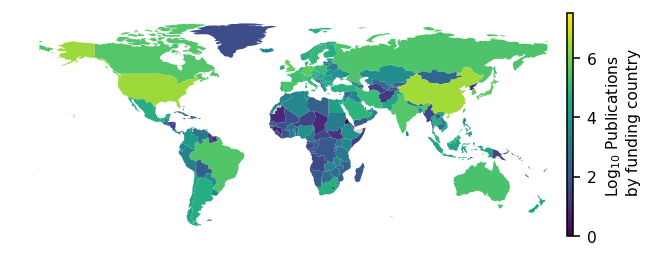

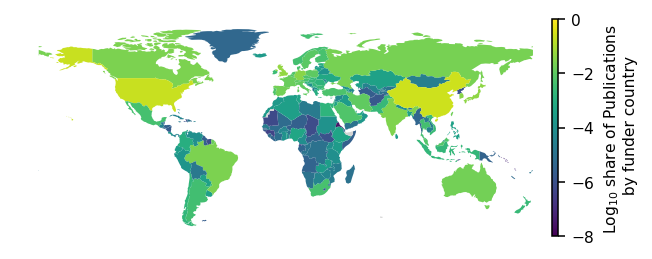

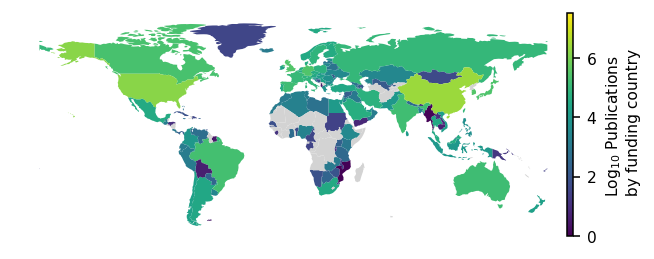

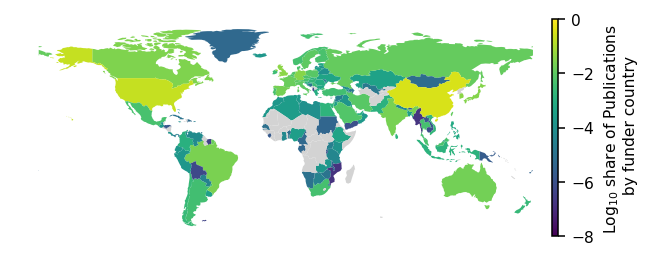

In [7]:
def map_figure_size(world, width_in=4.9):
    xmin, ymin, xmax, ymax = world.total_bounds
    w = xmax - xmin
    h = ymax - ymin
    aspect = w / h if h != 0 else 1.0
    height_in = width_in / aspect if aspect > 0 else width_in
    return width_in, height_in


def plot_country_map_single(world, df, iso_col, value_col, legend_label, out_name, *, log10=False, vmin=None, vmax=None, cmap=None):
    if world is None:
        print(f'Skipping {out_name}: world geometry not loaded.')
        return

    pdf = df.to_pandas()
    merged = world.merge(pdf, how='left', left_on='ISO_A2_EH', right_on=iso_col)
    plot_col = value_col
    if log10:
        plot_col = f'{value_col}_plot'
        merged[plot_col] = np.log10(merged[value_col])

    width_in, height_in = map_figure_size(world)
    fig, ax = plt.subplots(1, 1, figsize=(width_in, height_in))
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='1%', pad=-0.1)

    merged.plot(
        column=plot_col,
        ax=ax,
        cax=cax,
        legend=True,
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        legend_kwds={'label': legend_label},
        missing_kwds={'color': 'lightgrey'},
    )

    sns.despine(left=True, bottom=True)
    ax.tick_params(bottom=False, left=False, labelbottom=False, labelleft=False)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / out_name, bbox_inches='tight')
    plt.show()


plot_country_map_single(
    world,
    wos_funder_country,
    'funder_countries',
    'fractional_funded_paper_count',
    'Log$_{10}$ Publications \n by funding country',
    'wos_log_funder.pdf',
    log10=True,
    vmin=0,
    vmax=7.5,
)

plot_country_map_single(
    world,
    wos_funder_country,
    'funder_countries',
    'global_share',
    'Log$_{10}$ share of Publications \n by funder country',
    'wos_global_share_funder.pdf',
    log10=True,
    vmin=-8,
    vmax=0,
)

plot_country_map_single(
    world,
    openalex_funder_country,
    'funder_countries',
    'fractional_funded_paper_count',
    'Log$_{10}$ Publications \n by funding country',
    'oa_log_funder.pdf',
    log10=True,
    vmin=0,
    vmax=7.5,
)

plot_country_map_single(
    world,
    openalex_funder_country,
    'funder_countries',
    'global_share',
    'Log$_{10}$ share of Publications \n by funder country',
    'oa_global_share_funder.pdf',
    log10=True,
    vmin=-8,
    vmax=0,
)


## Funding by author country


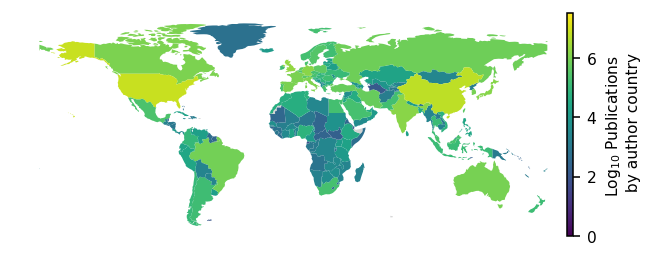

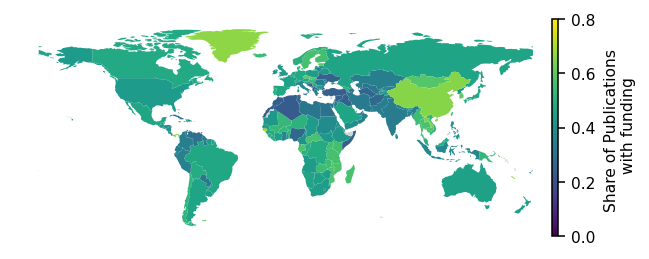

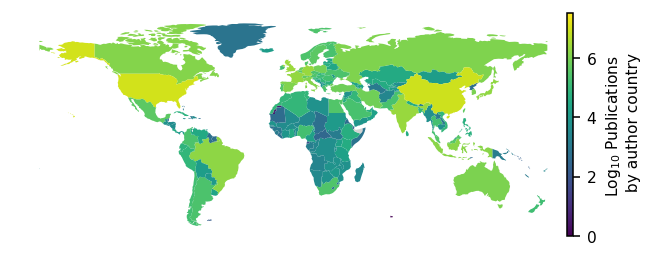

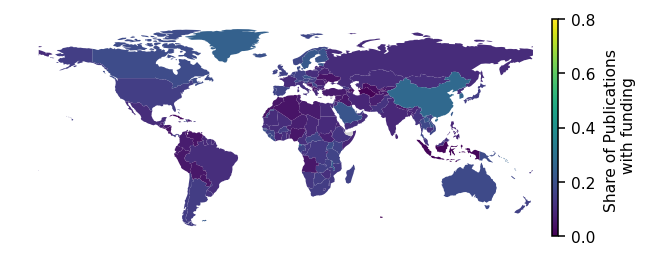

In [22]:
plot_country_map_single(
    world,
    wos_author_country,
    'auth_countries',
    'fractional_funded_paper_count',
    'Log$_{10}$ Publications \n by author country',
    'wos_log_author.pdf',
    log10=True,
    vmin=0,
    vmax=7.5,
)

plot_country_map_single(
    world,
    wos_author_country,
    'auth_countries',
    'share_has_grant',
    'Share of Publications \n with funding',
    'wos_share_author.pdf',
    log10=False,
    vmin=0,
    vmax=0.8,
)

plot_country_map_single(
    world,
    openalex_author_country,
    'auth_countries',
    'fractional_funded_paper_count',
    'Log$_{10}$ Publications \n by author country',
    'oa_log_author.pdf',
    log10=True,
    vmin=0,
    vmax=7.5,
)

plot_country_map_single(
    world,
    openalex_author_country,
    'auth_countries',
    'share_has_grant',
    'Share of Publications \n with funding',
    'oa_share_author.pdf',
    log10=False,
    vmin=0,
    vmax=0.8,
)


## Funder sector composition


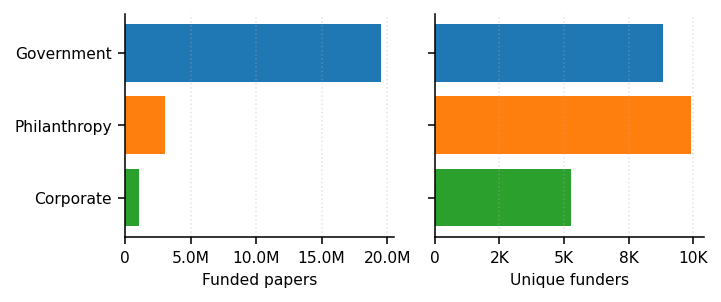

In [23]:
sector_summary = (
    wos_funder_types
    .filter(pl.col('oa_ancestortypes').is_not_null())
    .group_by('oa_ancestortypes')
    .agg(
        pl.col('n_pubs').sum().alias('n_pubs'),
        pl.col('id').n_unique().alias('n_funders'),
    )
    .sort('n_pubs', descending=True)
)

labels = {
    'government': 'Government',
    'nonprofit': 'Philanthropy',
    'company': 'Corporate',
}

sector_plot = sector_summary.with_columns(
    pl.col('oa_ancestortypes').replace(labels).alias('label')
)

fig, axes = plt.subplots(1, 2, figsize=(5.2, 2.2), sharey=True)

axes[0].barh(sector_plot['label'], sector_plot['n_pubs'], color=sns.color_palette('tab10', sector_plot.height))
axes[0].invert_yaxis()
axes[0].set_xlabel('Funded papers')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(format_large_tick))
axes[0].spines[['top', 'right']].set_visible(False)
axes[0].grid(axis='x', linestyle=':', alpha=0.35)

axes[1].barh(sector_plot['label'], sector_plot['n_funders'], color=sns.color_palette('tab10', sector_plot.height))
axes[1].set_xlabel('Unique funders')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(format_large_tick))
axes[1].spines[['top', 'right']].set_visible(False)
axes[1].grid(axis='x', linestyle=':', alpha=0.35)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'sector_coverage.pdf', bbox_inches='tight')
plt.show()


## Funder concentration / rank-frequency


/var/folders/y6/k76sh60x15b90z0gvgbfk3xc0000gn/T/ipykernel_39468/2328824042.py:156: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


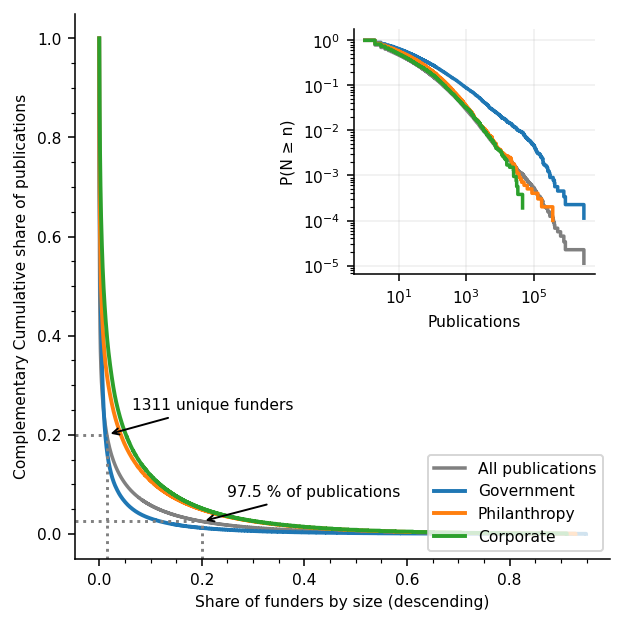

In [8]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.ticker import AutoMinorLocator

df_funder_stats = (
    wos_funder_types
)

df_sorted_pubs = (
    df_funder_stats
    .select('id', 'n_pubs', 'oa_ancestortypes')
    .with_columns(pl.col('n_pubs').rank(descending=False).alias('rank'))
    .sort('n_pubs', descending=False)
    .with_columns(pl.col('n_pubs').cum_sum().alias('cum_n_pubs'))
)

total_pubs_sponsored = df_sorted_pubs.select(pl.col('n_pubs').sum()).item()
num_funders = df_sorted_pubs.height

df_sorted_pubs = df_sorted_pubs.with_columns(
    (pl.col('cum_n_pubs') / total_pubs_sponsored).alias('fraction_of_pubs'),
    ((pl.col('rank') - 1) / max(num_funders - 1, 1)).alias('norm_rank'),
    (pl.arange(1, num_funders + 1) / num_funders).alias('fraction_of_funders'),
)

df_ranked = (
    df_funder_stats
    .sort(['oa_ancestortypes', 'n_pubs'], descending=[True, False])
    .with_columns(
        pl.col('n_pubs').rank('average', descending=False).over('oa_ancestortypes').alias('rank'),
        pl.len().over('oa_ancestortypes').alias('n_funders_in_type'),
    )
    .with_columns(
        ((pl.col('rank') - 1) / (pl.col('n_funders_in_type') - 1)).fill_nan(0).fill_null(0).alias('rank_norm')
    )
)

df_cum = (
    df_ranked
    .sort(['oa_ancestortypes', 'n_pubs'], descending=[True, False])
    .with_columns(
        (pl.col('n_pubs').cum_sum().over('oa_ancestortypes') / pl.col('n_pubs').sum().over('oa_ancestortypes')).alias('cum_share_outcomes')
    )
)

ccdf_overall = (
    df_funder_stats
    .group_by('n_pubs')
    .len()
    .rename({'len': 'freq'})
    .sort('n_pubs')
    .with_columns(
        pl.col('freq').reverse().cum_sum().reverse().alias('survival_count'),
        pl.col('freq').sum().alias('total_funders'),
    )
    .with_columns((pl.col('survival_count') / pl.col('total_funders')).alias('ccdf'))
    .select('n_pubs', 'ccdf')
)

ccdf_by_type = (
    df_funder_stats
    .select('oa_ancestortypes', 'n_pubs')
    .group_by(['oa_ancestortypes', 'n_pubs'])
    .len()
    .rename({'len': 'freq'})
    .sort(['oa_ancestortypes', 'n_pubs'])
    .with_columns(
        pl.col('freq').reverse().cum_sum().reverse().over('oa_ancestortypes').alias('survival_count'),
        pl.col('freq').sum().over('oa_ancestortypes').alias('total_funders_type'),
    )
    .with_columns((pl.col('survival_count') / pl.col('total_funders_type')).alias('ccdf'))
    .select('oa_ancestortypes', 'n_pubs', 'ccdf')
)

pdf_pubs = df_sorted_pubs.to_pandas()
pdf_pubs['desc_rank'] = 1 - pdf_pubs['norm_rank']

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

ax.plot(
    pdf_pubs['desc_rank'],
    pdf_pubs['fraction_of_pubs'],
    label='All publications',
    color='gray',
    linestyle='-',
)

order = ['government', 'nonprofit', 'company']
labels_map = {'government': 'Government', 'nonprofit': 'Philanthropy', 'company': 'Corporate'}

for t in order:
    sub = df_cum.filter(pl.col('oa_ancestortypes') == t).to_pandas()
    if len(sub) == 0:
        continue
    ax.plot(1 - sub['rank_norm'], sub['cum_share_outcomes'], label=labels_map.get(t, t), linewidth=2)

ymin, ymax = ax.get_ylim()
xmin, xmax = ax.get_xlim()

threshold = 0.2
drop_80_value = np.interp(threshold, pdf_pubs['desc_rank'][::-1], pdf_pubs['fraction_of_pubs'][::-1])

xmin_rel = (threshold - xmin) / (xmax - xmin)
ymax_rel = (drop_80_value - ymin) / (ymax - ymin)

ax.axvline(x=threshold, ymax=ymax_rel, color='gray', linestyle='dotted', linewidth=1.5)
ax.axhline(y=drop_80_value, xmax=xmin_rel, color='gray', linestyle='dotted', linewidth=1.5)
ax.annotate(
    f"{round(1-drop_80_value, 3) * 100} % of publications",
    xy=(threshold, drop_80_value),
    xytext=(threshold + 0.05, drop_80_value + 0.05),
    arrowprops=dict(facecolor='black', arrowstyle='->'),
)

threshold = 0.2
drop_80_value = np.interp(threshold, pdf_pubs['fraction_of_pubs'], pdf_pubs['desc_rank'])
funder_count = int(np.floor(drop_80_value * num_funders))

xmin_rel = (drop_80_value - xmin) / (xmax - xmin)
ymax_rel = (threshold - ymin) / (ymax - ymin)

ax.axvline(x=drop_80_value, ymax=ymax_rel, color='gray', linestyle='dotted', linewidth=1.5)
ax.axhline(y=threshold, xmax=xmin_rel, color='gray', linestyle='dotted', linewidth=1.5)
ax.annotate(
    f"{funder_count} unique funders",
    xy=(drop_80_value, threshold),
    xytext=(drop_80_value + 0.05, threshold + 0.05),
    arrowprops=dict(facecolor='black', arrowstyle='->'),
)

ax.legend(loc='lower right')
ax.spines[['right', 'top']].set_visible(False)
ax.set_xlabel('Share of funders by size (descending)')
ax.set_ylabel('Complementary Cumulative share of publications')
ax.tick_params(axis='both', which='major')

ax_inset = inset_axes(ax, width='45%', height='45%', loc='upper right', borderpad=1.0)
co = ccdf_overall.to_pandas().sort_values('n_pubs')
ax_inset.step(co['n_pubs'], co['ccdf'], where='post', color='gray')
ax_inset.set_xscale('log')
ax_inset.set_yscale('log')
ax_inset.set_xlabel('Publications')
ax_inset.set_ylabel('P(N ≥ n)')
ax_inset.grid(True, which='major', alpha=0.2)
ax_inset.spines[['right', 'top']].set_visible(False)

for t in order:
    sub = ccdf_by_type.filter(pl.col('oa_ancestortypes') == t).to_pandas()
    if len(sub) == 0:
        continue
    ax_inset.step(sub['n_pubs'], sub['ccdf'], where='post', label=labels_map.get(t, t))

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'complementary_share_P.pdf', bbox_inches='tight')
plt.show()


## Appendix: Polars recipes for DOI comparison

These recipes are intentionally compact in code, but they expect a specific minimal schema. If a source uses different column names, the easiest approach is to rename them into the expected shape first and then apply the recipe unchanged.

`recipe_wos_doi_to_ror(papers_lf, matched_grants_lf)` expects two lazy frames. `papers_lf` must contain at least `UID` and `doi`, where `UID` is the paper identifier used to join against the matched-funder table and `doi` is the paper DOI in string form. `matched_grants_lf` must contain at least `UID` and `ids:ror`, where `ids:ror` is the matched ROR identifier for each linked funder mention. The recipe joins on `UID`, removes rows with missing or empty DOIs and RORs, and returns one row per DOI with a list column `ids:ror` containing the unique matched RORs observed for that DOI.

`recipe_openalex_doi_to_ror(works_lf, funders_lf)` expects the OpenAlex works table in a form where `works_lf` contains `ids` and `grants`. The `ids` column must be a struct with a `doi` field, and `grants` must be a list column whose elements can be decoded into a struct with fields `funder`, `funder_display_name`, and `award_id`. The companion `funders_lf` table must contain `id` and `ids:ror`, where `id` is the OpenAlex funder identifier used in the grant record and `ids:ror` is the corresponding ROR identifier. The recipe explodes grant records, normalizes the DOI by stripping the `https://doi.org/` prefix, joins funders to their ROR IDs, and returns one row per DOI with a list column `ror` containing the unique matched RORs.

`apply_ror_rank(df, list_col, ror_rank_df, out_col)` is used when the comparison should be performed at the parent-ROR level rather than the raw institution level. It expects a DOI-level table `df` that already contains a list column of ROR IDs, named by `list_col`. The mapping table `ror_rank_df` must contain columns `id` and `rank`, where `id` is the original ROR identifier and `rank` is the collapsed parent or root identifier that should be used for comparison. The function writes a new list column named by `out_col` in which each ROR has been replaced by its parent/root rank and deduplicated within DOI.

`recipe_direct_doi_overlap(left_lf, right_lf, left_col, right_col)` expects two DOI-level tables where both sides have a `doi` column and one list column of comparable funder identifiers. These list columns are usually the parent-collapsed ROR columns created by `apply_ror_rank`, for example `parent_wos` and `parent_oa`. The function performs an inner join on DOI and then computes three comparison outputs: `hit_rate`, which is `True` when the two funder sets intersect at all for a DOI; `complete_right`, which is `True` when the right-hand funder set is fully contained in the left-hand set; and `complete_left`, which is `True` when the left-hand funder set is fully contained in the right-hand set.

In practice, the DOI comparison pipeline therefore has three stages: first reduce each source database to a DOI-to-list-of-RORs table, then optionally collapse raw RORs to a parent/root level with `apply_ror_rank`, and only then compute DOI-level overlap statistics with `recipe_direct_doi_overlap`.


In [25]:
# --- DOI-based direct database comparison ---
# The direct comparison is easiest if each database is first reduced to a DOI -> list-of-RORs table.
# If you compare at the ROR-parent level, precompute a `ror_rank_df` table with columns: id, rank.


def recipe_wos_doi_to_ror(papers_lf: pl.LazyFrame, matched_grants_lf: pl.LazyFrame) -> pl.LazyFrame:
    return (
        papers_lf
        .select('UID', 'doi')
        .join(matched_grants_lf.select('UID', 'ids:ror'), on='UID', how='inner')
        .filter(pl.col('doi').is_not_null() & (pl.col('doi') != ''))
        .filter(pl.col('ids:ror').is_not_null() & (pl.col('ids:ror') != ''))
        .group_by('doi')
        .agg(pl.col('ids:ror').unique())
    )


def recipe_openalex_doi_to_ror(works_lf: pl.LazyFrame, funders_lf: pl.LazyFrame) -> pl.LazyFrame:
    grant_struct = pl.Struct([
        pl.Field('funder', pl.String),
        pl.Field('funder_display_name', pl.String),
        pl.Field('award_id', pl.String),
    ])
    return (
        works_lf
        .filter(pl.col('grants').list.len() > 0)
        .select('ids', 'grants')
        .explode('grants')
        .with_columns(
            pl.col('grants').str.json_decode(dtype=grant_struct),
            pl.col('ids').struct.field('doi').str.replace(r'^https?://doi.org/', '', literal=False).alias('doi'),
        )
        .drop('ids')
        .unnest('grants')
        .join(funders_lf.select(pl.col('id').alias('funder'), pl.col('ids:ror').alias('ror')), on='funder', how='left')
        .group_by('doi')
        .agg(pl.col('ror').drop_nulls().unique())
    )


def apply_ror_rank(df: pl.LazyFrame, list_col: str, ror_rank_df: pl.DataFrame, out_col: str) -> pl.LazyFrame:
    return df.with_columns(
        pl.col(list_col).list.eval(pl.element().replace(ror_rank_df['id'], ror_rank_df['rank']).unique()).alias(out_col)
    )


def recipe_direct_doi_overlap(left_lf: pl.LazyFrame, right_lf: pl.LazyFrame, left_col: str, right_col: str) -> pl.LazyFrame:
    return (
        left_lf
        .join(right_lf, on='doi', how='inner')
        .with_columns(
            (pl.col(left_col).list.set_intersection(right_col).list.len() > 0).alias('hit_rate'),
            (pl.col(right_col).list.set_intersection(left_col) == pl.col(right_col)).alias('complete_right'),
            (pl.col(left_col).list.set_intersection(right_col) == pl.col(left_col)).alias('complete_left'),
        )
    )


# Example usage after parent-level collapsing:
# wos_doi = apply_ror_rank(recipe_wos_doi_to_ror(wos_papers_lf, matched_grants_lf), 'ids:ror', ror_rank_df, 'parent_wos')
# oa_doi = apply_ror_rank(recipe_openalex_doi_to_ror(oa_works_lf, oa_funders_lf), 'ror', ror_rank_df, 'parent_oa')
# oa_vs_wos = recipe_direct_doi_overlap(oa_doi, wos_doi, 'parent_oa', 'parent_wos')


In [26]:
# --- Coverage over time ---

def recipe_wos_share(papers_lf: pl.LazyFrame, matched_grants_lf: pl.LazyFrame) -> pl.LazyFrame:
    funded = matched_grants_lf.select('UID').unique().with_columns(pl.lit(True).alias('has_grant'))
    return (
        papers_lf
        .select('UID', 'pubyear')
        .join(funded, on='UID', how='left')
        .group_by('pubyear')
        .agg(
            pl.len().alias('total_pubs'),
            pl.col('has_grant').sum().alias('pubs_with_grant'),
        )
        .with_columns((pl.col('pubs_with_grant') / pl.col('total_pubs')).alias('share_with_grant'))
        .sort('pubyear')
    )


def recipe_openalex_share(works_lf: pl.LazyFrame) -> pl.LazyFrame:
    return (
        works_lf
        .with_columns((pl.col('grants').list.len() > 0).alias('has_grant'))
        .group_by('publication_year')
        .agg(
            pl.len().alias('total_pubs'),
            pl.col('has_grant').sum().alias('pubs_with_grant'),
        )
        .with_columns((pl.col('pubs_with_grant') / pl.col('total_pubs')).alias('share_with_grant'))
        .sort('publication_year')
    )


# --- Country-of-funder coverage ---

def recipe_wos_funder_country(matched_grants_lf: pl.LazyFrame) -> pl.LazyFrame:
    return (
        matched_grants_lf
        .select('UID', pl.col('funder_country_code').alias('funder_country'))
        .group_by('UID')
        .agg(pl.col('funder_country').drop_nulls().alias('funder_countries'))
        .with_columns(pl.col('funder_countries').list.len().alias('n_funders'))
        .explode('funder_countries')
        .with_columns((1 / pl.col('n_funders')).alias('funder_fraction'))
        .group_by('funder_countries')
        .agg(
            pl.sum('funder_fraction').alias('fractional_funded_paper_count'),
        )
        .with_columns(
            (pl.col('fractional_funded_paper_count') / pl.col('fractional_funded_paper_count').sum()).alias('global_share')
        )
        .sort('fractional_funded_paper_count', descending=True)
    )


def recipe_openalex_funder_country(works_lf: pl.LazyFrame, funders_lf: pl.LazyFrame) -> pl.LazyFrame:
    grant_struct = pl.Struct([
        pl.Field('funder', pl.String),
        pl.Field('funder_display_name', pl.String),
        pl.Field('award_id', pl.String),
    ])
    oa_grants = (
        works_lf
        .filter(pl.col('grants').list.len() > 0)
        .select('id', 'grants')
        .explode('grants')
        .with_columns(pl.col('grants').str.json_decode(dtype=grant_struct))
        .select('id', pl.col('grants').struct.field('funder').alias('funder'))
        .join(funders_lf.select(pl.col('id').alias('funder'), 'country_code'), on='funder', how='left')
    )
    return (
        oa_grants
        .select('id', pl.col('country_code').alias('funder_country'))
        .group_by('id')
        .agg(pl.col('funder_country').drop_nulls().alias('funder_countries'))
        .with_columns(pl.col('funder_countries').list.len().alias('n_funders'))
        .explode('funder_countries')
        .with_columns((1 / pl.col('n_funders')).alias('funder_fraction'))
        .group_by('funder_countries')
        .agg(pl.sum('funder_fraction').alias('fractional_funded_paper_count'))
        .with_columns(
            (pl.col('fractional_funded_paper_count') / pl.col('fractional_funded_paper_count').sum()).alias('global_share')
        )
        .sort('fractional_funded_paper_count', descending=True)
    )


# --- Country-of-author coverage ---

def recipe_wos_author_country(authors_lf: pl.LazyFrame, matched_grants_lf: pl.LazyFrame) -> pl.LazyFrame:
    funded = matched_grants_lf.select('UID').unique().with_columns(pl.lit(1).alias('has_grant'))
    return (
        authors_lf
        .select('UID', 'country_code')
        .filter(pl.col('country_code').is_not_null())
        .unique()
        .group_by('UID')
        .agg(pl.col('country_code').alias('auth_countries'))
        .with_columns(pl.col('auth_countries').list.len().alias('n_auth_countries'))
        .explode('auth_countries')
        .with_columns((1 / pl.col('n_auth_countries')).alias('author_fraction'))
        .join(funded, on='UID', how='left')
        .with_columns(pl.col('has_grant').fill_null(0))
        .group_by('auth_countries')
        .agg(
            pl.col('has_grant').mean().alias('share_has_grant'),
            pl.sum('author_fraction').alias('fractional_funded_paper_count'),
        )
        .sort('fractional_funded_paper_count', descending=True)
    )


def recipe_openalex_author_country(works_lf: pl.LazyFrame) -> pl.LazyFrame:
    return (
        works_lf
        .select(
            pl.col('authorships').list.eval(
                pl.element().struct.field('countries').list.explode()
            ).list.unique().alias('auth_countries'),
            (pl.col('grants').list.len() > 0).alias('has_grant'),
        )
        .with_columns(pl.col('auth_countries').list.len().alias('n_auth_countries'))
        .explode('auth_countries')
        .with_columns((1 / pl.col('n_auth_countries')).alias('author_fraction'))
        .group_by('auth_countries')
        .agg(
            pl.col('has_grant').mean().alias('share_has_grant'),
            pl.sum('author_fraction').alias('fractional_funded_paper_count'),
        )
        .sort('fractional_funded_paper_count', descending=True)
    )


# --- Funder sectors and concentration ---

def recipe_funder_type_stats(matched_grants_lf: pl.LazyFrame) -> pl.LazyFrame:
    return (
        matched_grants_lf
        .group_by('id')
        .agg(
            pl.col('oa_ancestortypes').first(),
            pl.len().alias('n_grants'),
            pl.col('UID').n_unique().alias('n_pubs'),
        )
        .filter(pl.col('id').is_not_null())
    )
